# STATS 425 · Week 5 lab
**Baselines and group-relative advantages**  
**TA:** Ali Kaazempur-Mofrad

In Week 4, we trained a policy with REINFORCE: sample an answer, check it with a verifier, and increase the log-probability of answers that earned a reward. Today, we make three changes that bring this closer to how language models are trained with verifiable rewards. Responses now contain several tokens. Each reward is compared with a **baseline** before it is used. That baseline comes from a **group** of responses to the same prompt, as in **group relative policy optimization (GRPO)**. We finish by adding a penalty that keeps the trained policy close to a **reference policy**.

**How this maps to a language model.** As in Week 4, our model reads numbers directly; it is not a pretrained language model. Its response, however, is now a short sequence of tokens generated one at a time, as in Week 3. The log-probability of a response is therefore a sum over its tokens, as in Weeks 1 and 2.

| Section | Question we answer |
|---|---|
| 1. Responses with several tokens | How do we assign a probability to a whole response? |
| 2. Why subtract a baseline? | Can we change the rewards used in an update without changing what the update estimates? |
| 3. Group-relative advantages | How does GRPO compare each response with others for the same prompt? |
| 4. Comparing three training rules | Do baselines and group-relative advantages change training in practice? |
| 5. Staying close to a reference policy | What does a KL penalty trade off? |

**Set up the notebook.** The cell below imports the libraries and sets a random seed so the results are repeatable; exact numbers may differ slightly across PyTorch versions.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("torch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch>=2.8,<3"])

import copy
import itertools
import math
import random

import matplotlib.pyplot as plt
import torch
from torch import nn  # PyTorch's neural-network module
from torch.distributions import Categorical

SEED = 425
torch.manual_seed(SEED)
torch.set_num_threads(1)

print(f"Setup complete. PyTorch {torch.__version__}")

Setup complete. PyTorch 2.8.0+cu128


## 1 · Responses with several tokens

We extend Week 4's task. The prompt still shows three different integers from 1 through 9, labeled A, B, and C. Now the response must **rank the letters from the largest number to the smallest**:

```text
Rank the letters from largest to smallest number.
A: 2    B: 7    C: 4
Respond with three letters.
```

The correct response is `B C A`: 7, then 4, then 2. The verifier gives reward 1 only if the whole ranking is correct:

$$
R(x,y)=
\begin{cases}
1, & \text{if response }y\text{ lists the letters in decreasing order of their numbers in }x,\\
0, & \text{otherwise.}
\end{cases}
$$

The response $y=(y_1,y_2,y_3)$ has three tokens, and each token is `A`, `B`, or `C`. We allow any letter at each position, so a response such as `B B A` is possible; it receives reward 0. There are $3^3=27$ possible responses, and exactly one of them is correct.

**The probability of a whole response.** The policy chooses tokens one at a time, as a language model does in Week 3. By the multiplication rule of probability,

$$
\pi_\theta(y\mid x)=\prod_{t=1}^{3}\pi_\theta(y_t\mid x,y_{<t}),
\qquad
\ln\pi_\theta(y\mid x)=\sum_{t=1}^{3}\ln\pi_\theta(y_t\mid x,y_{<t}).
$$

Here $y_{<t}$ denotes the tokens chosen before position $t$. This is the same sum of token log-probabilities we used for a sentence in Week 1 and for a response in Week 2.

**Our policy.** At each position $t$, the model computes one logit per letter from two inputs and applies softmax, as in Week 4:

$$
z_t=Wu+Vh_t,
\qquad
\pi_\theta(y_t=j\mid x,y_{<t})=\frac{e^{z_{t,j}}}{\sum_{k\in\{A,B,C\}}e^{z_{t,k}}}.
$$

- $u=\frac{1}{10}(x_A,x_B,x_C)^\top$ contains the scaled numbers, exactly as in Week 4.
- $h_t$ counts how many times each letter has already been chosen. After the tokens `B C`, for example, $h_3=(0,1,1)^\top$. At the first position, $h_1=(0,0,0)^\top$.
- $W$ and $V$ are learned $3\times3$ matrices, so $\theta=(W,V)$ contains 18 weights. The same weights are used at every position, as in a language model; only the input $h_t$ changes.

We start with $W$ and $V$ equal to zero. Every logit is then zero, and every letter has probability $1/3$ at every position.

<details><summary>Can this small model represent the correct rule?</summary>

Yes. Take $W=cI$ and $V=-mI$, where $I$ is the $3\times3$ identity matrix and $c,m>0$. Then $z_{t,j}=c\,u_j-m\,h_{t,j}$: a letter's logit grows with its number and drops by $m$ each time the letter has been used. If $m$ is large compared with $c$, the most likely token is the unused letter with the largest number. Making both $c$ and $m$ large (with $m$ still large compared with $c$) pushes each of these probabilities toward 1. Training has to discover weights like these from rewards alone.

</details>

**Predict before running:** under the starting policy, what is the probability of the correct response `B C A`? What is the probability of `A A A`?

**Sample one response, one token at a time.** The code below defines the verifier and the policy. It samples one response to the example prompt and prints, for each position, the probabilities of the three letters, the sampled token, and that token's log-probability. The last lines add the log-probabilities and convert the sum back into a probability.

In [2]:
LETTERS = ("A", "B", "C")
EXAMPLE = (2, 7, 4)
RESPONSE_LENGTH = 3


def format_prompt(numbers):
    options = "    ".join(f"{letter}: {int(value)}" for letter, value in zip(LETTERS, numbers))
    return f"Rank the letters from largest to smallest number.\n{options}\nRespond with three letters."


def to_text(response):
    return " ".join(LETTERS[token] for token in response)


def correct_rankings(numbers):
    # Letter indices ordered from the largest number to the smallest.
    return torch.argsort(numbers, dim=1, descending=True)


def ranking_rewards(numbers, responses):
    # Reward 1 only if all three tokens match the correct ranking.
    return (responses == correct_rankings(numbers)).all(dim=1).float()


class RankingPolicy(nn.Module):
    def __init__(self):
        super().__init__()
        self.W = nn.Parameter(torch.zeros(3, 3))  # weights for the scaled numbers u
        self.V = nn.Parameter(torch.zeros(3, 3))  # weights for the letter counts h_t

    def next_token_distribution(self, numbers, counts):
        logits = (numbers / 10.0) @ self.W.T + counts @ self.V.T
        return Categorical(logits=logits)


def run_policy(policy, numbers, responses=None):
    # Generate one token at a time. If responses are given, score them instead of sampling.
    counts = torch.zeros_like(numbers)
    tokens, log_probs = [], []
    for t in range(RESPONSE_LENGTH):
        distribution = policy.next_token_distribution(numbers, counts)
        token = distribution.sample() if responses is None else responses[:, t]
        tokens.append(token)
        log_probs.append(distribution.log_prob(token))
        counts = counts + nn.functional.one_hot(token, 3).float()
    return torch.stack(tokens, dim=1), torch.stack(log_probs, dim=1)


def sample_responses(policy, numbers):
    return run_policy(policy, numbers)


def token_log_probs(policy, numbers, responses):
    return run_policy(policy, numbers, responses)[1]


@torch.no_grad()
def show_response(policy, numbers, response):
    numbers = torch.tensor([numbers], dtype=torch.float32)
    counts = torch.zeros_like(numbers)
    total = 0.0
    print(f"{'Position':<10}{'Chosen before':<15}{'P(A)':>8}{'P(B)':>8}{'P(C)':>8}"
          f"{'Token':>8}{'ln p(token)':>14}")
    for t, token in enumerate(response):
        probabilities = policy.next_token_distribution(numbers, counts).probs[0]
        log_p = math.log(probabilities[token].item())
        total += log_p
        before = to_text(response[:t]) or "(none)"
        print(f"{t + 1:<10}{before:<15}" + "".join(f"{p:>8.4f}" for p in probabilities.tolist())
              + f"{LETTERS[token]:>8}{log_p:>14.4f}")
        counts[0, token] += 1
    print(f"Sum of token log-probabilities = {total:.4f}")
    print(f"Probability of the whole response = exp({total:.4f}) = {math.exp(total):.4f}")


torch.manual_seed(SEED)
initial_policy = RankingPolicy()
demo_numbers = torch.tensor([EXAMPLE], dtype=torch.float32)
demo_response, _ = sample_responses(initial_policy, demo_numbers)
demo_response = demo_response[0].tolist()

print(format_prompt(EXAMPLE))
print("-" * 71)
print(f"SAMPLED RESPONSE: {to_text(demo_response)}")
show_response(initial_policy, EXAMPLE, demo_response)
print(f"Reward = {ranking_rewards(demo_numbers, torch.tensor([demo_response])).item():.0f}"
      f" (correct ranking: {to_text(correct_rankings(demo_numbers)[0].tolist())})")

Rank the letters from largest to smallest number.
A: 2    B: 7    C: 4
Respond with three letters.
-----------------------------------------------------------------------
SAMPLED RESPONSE: C C B
Position  Chosen before      P(A)    P(B)    P(C)   Token   ln p(token)
1         (none)           0.3333  0.3333  0.3333       C       -1.0986
2         C                0.3333  0.3333  0.3333       C       -1.0986
3         C C              0.3333  0.3333  0.3333       B       -1.0986
Sum of token log-probabilities = -3.2958
Probability of the whole response = exp(-3.2958) = 0.0370
Reward = 0 (correct ranking: B C A)


In the saved run, the sampled response `C C B` repeats a letter and earns reward 0. Every token had probability $1/3$, so each position contributes $\ln(1/3)\approx-1.0986$ and the sum is $3\ln(1/3)=\ln(1/27)\approx-3.2958$. **Every one of the 27 responses has probability $1/27\approx0.037$**, including the correct ranking `B C A` and the response `A A A`.

In Week 4, the uniform starting policy was correct one-third of the time. Here it is correct only $1/27$ of the time, so most sampled responses earn reward 0 at the start. Longer responses make a fully correct response rarer.

**A supervised start.** Reinforcement learning for language models usually begins from a model that has already been fine-tuned on desired responses, as in Week 2. For a response with several tokens, the supervised loss for one example is the negative log-likelihood (NLL) of the whole desired response $y^\star$:

$$
-\ln\pi_\theta(y^\star\mid x)=-\sum_{t=1}^{3}\ln\pi_\theta(y^\star_t\mid x,y^\star_{<t}).
$$

**Prepare the training and test sets.** We use the same split as Week 4: 64 groups of three numbers for training and 20 groups for testing, each group in all six orders. This gives 384 training prompts and 120 test prompts; no test prompt is a rearrangement of a training prompt.

We take only 30 supervised updates (Adam, learning rate 0.05, batch size 32) and then stop on purpose. The result is a **partly trained policy**. We use it in Section 2 to study gradient estimates, and in Section 5 as the reference policy.

**Measure performance.** We use the two quantities from Week 4:

- **Expected reward.** Exactly one response is correct, so $\mathbb{E}[R\mid x]=\pi_\theta(y^\star\mid x)$, the product of the three token probabilities along the correct ranking. We calculate it exactly and average over prompts.
- **Greedy accuracy.** At each position we choose the most likely token (greedy decoding, Week 3) and check the finished response. As Week 3 showed, choosing the best token at each step need not give the most likely whole response, but it is the usual greedy rule.

In [3]:
groups = list(itertools.combinations(range(1, 10), 3))
random.Random(SEED).shuffle(groups)
train_groups, test_groups = groups[:64], groups[64:]


def expand_orders(groups):
    return torch.tensor([
        ordering
        for group in groups
        for ordering in itertools.permutations(group)
    ], dtype=torch.float32)


train_numbers = expand_orders(train_groups)
test_numbers = expand_orders(test_groups)


@torch.no_grad()
def greedy_responses(policy, numbers):
    counts = torch.zeros_like(numbers)
    tokens = []
    for t in range(RESPONSE_LENGTH):
        token = policy.next_token_distribution(numbers, counts).probs.argmax(dim=1)
        tokens.append(token)
        counts = counts + nn.functional.one_hot(token, 3).float()
    return torch.stack(tokens, dim=1)


@torch.no_grad()
def measure_performance(policy, numbers):
    correct_log_probs = token_log_probs(policy, numbers, correct_rankings(numbers)).sum(dim=1)
    expected_reward = correct_log_probs.exp().mean().item()
    greedy_accuracy = ranking_rewards(numbers, greedy_responses(policy, numbers)).mean().item()
    return {"expected_reward": expected_reward, "greedy_accuracy": greedy_accuracy}


torch.manual_seed(SEED)
supervised_policy = copy.deepcopy(initial_policy)
optimizer = torch.optim.Adam(supervised_policy.parameters(), lr=0.05)
for update in range(30):
    batch = train_numbers[torch.randint(len(train_numbers), (32,))]
    loss = -token_log_probs(supervised_policy, batch, correct_rankings(batch)).sum(dim=1).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f"Training set: {len(train_groups)} groups x 6 orders = {len(train_numbers)} prompts")
print(f"Test set: {len(test_groups)} groups x 6 orders = {len(test_numbers)} prompts")
print("=" * 72)
print(f"{'Set':<14}{'Metric':<18}{'Uniform start':>16}{'After 30 SFT updates':>24}")
for split_name, numbers in [("Training set", train_numbers), ("Test set", test_numbers)]:
    before = measure_performance(initial_policy, numbers)
    after = measure_performance(supervised_policy, numbers)
    print(f"{split_name:<14}{'Expected reward':<18}{before['expected_reward']:>16.4f}{after['expected_reward']:>24.4f}")
    print(f"{'':<14}{'Greedy accuracy':<18}{before['greedy_accuracy']:>16.1%}{after['greedy_accuracy']:>24.1%}")
print("=" * 72)
print(f"CORRECT RESPONSE {to_text(correct_rankings(demo_numbers)[0].tolist())} UNDER THE SUPERVISED POLICY")
show_response(supervised_policy, EXAMPLE, correct_rankings(demo_numbers)[0].tolist())

Training set: 64 groups x 6 orders = 384 prompts
Test set: 20 groups x 6 orders = 120 prompts
Set           Metric               Uniform start    After 30 SFT updates
Training set  Expected reward             0.0370                  0.2122
              Greedy accuracy               0.0%                  100.0%
Test set      Expected reward             0.0370                  0.2119
              Greedy accuracy               0.0%                  100.0%
CORRECT RESPONSE B C A UNDER THE SUPERVISED POLICY
Position  Chosen before      P(A)    P(B)    P(C)   Token   ln p(token)
1         (none)           0.1855  0.5457  0.2688       B       -0.6057
2         B                0.3630  0.0806  0.5564       C       -0.5862
3         B C              0.7577  0.1553  0.0870       A       -0.2775
Sum of token log-probabilities = -1.4694
Probability of the whole response = exp(-1.4694) = 0.2301


After only 30 updates, greedy decoding produces the correct ranking on every training and test prompt, yet the expected reward is only about 0.21. The token-by-token table shows why: each correct token is the most likely choice, but none is close to certain, and **the probability of a whole response is the product of its token probabilities**. Here the three correct tokens have probabilities of roughly 0.55, 0.56, and 0.76, and their product is only about 0.23.

The uniform start has greedy accuracy 0%. All three probabilities are tied at every position, `argmax` then picks the first letter, and the greedy response is always `A A A`.

Notice also that the probabilities at positions 2 and 3 differ from those at position 1, even though the weights are the same. The counts $h_t$ make letters that have already been used less likely.

## 2 · Why subtract a baseline?

In Week 4, the REINFORCE loss for a batch of $B$ sampled responses was $L(\theta)=-\frac{1}{B}\sum_i r_i\ln\pi_\theta(y_i\mid x_i)$. Its negative gradient,

$$
\hat g=\frac{1}{B}\sum_{i=1}^{B} r_i\,\nabla_\theta\ln\pi_\theta(y_i\mid x_i),
$$

is a **random estimate** of the policy gradient $\nabla_\theta J(\theta)$, where $J(\theta)$ is the expected reward. It is random because the prompts and responses are sampled. On average it equals the policy gradient, but any single batch can point somewhere else. The spread of $\hat g$ from batch to batch, its variance, determines how noisy each update is.

**A baseline.** Replace each reward $r_i$ by $r_i-b$, where $b$ is a number that does not depend on the sampled response:

$$
\hat g_b=\frac{1}{B}\sum_{i=1}^{B}(r_i-b)\,\nabla_\theta\ln\pi_\theta(y_i\mid x_i).
$$

The difference $r_i-b$ is called an **advantage**: how much better the response did than the baseline. A response with $r_i>b$ is made more likely; a response with $r_i<b$ is made less likely.

**Why the expected gradient does not change.** For a fixed prompt $x$, the expected value of the log-probability gradient is zero:

$$
\mathbb{E}_{y\sim\pi_\theta(\cdot\mid x)}\big[\nabla_\theta\ln\pi_\theta(y\mid x)\big]
=\sum_{y}\pi_\theta(y\mid x)\,\frac{\nabla_\theta\pi_\theta(y\mid x)}{\pi_\theta(y\mid x)}
=\nabla_\theta\sum_{y}\pi_\theta(y\mid x)
=\nabla_\theta 1=0.
$$

The first step uses $\nabla\ln f=\nabla f/f$; the last uses the fact that the probabilities of all 27 responses add up to 1 for every value of $\theta$. Therefore

$$
\mathbb{E}\big[(R-b)\nabla_\theta\ln\pi_\theta(y\mid x)\big]
=\mathbb{E}\big[R\,\nabla_\theta\ln\pi_\theta(y\mid x)\big]-b\cdot 0
=\nabla_\theta J(\theta).
$$

The same argument works if $b$ depends on the prompt $x$, but not if it depends on the sampled response $y$ itself.

**A baseline changes only the noise.** Subtracting $b$ cannot change the expected gradient, but it does change the variance. A useful special case: adding 1 to every reward is the same as using the baseline $b=-1$. Real reward functions often include such offsets, for example a point for following the required format. With the 0/1 reward, every response that is wrong scores 0; with an extra point for a well-formed response, every response here (all of them have three letters) would score at least 1.

<details><summary>Which constant gives the smallest variance?</summary>

Write $\ell=\ln\pi_\theta(y\mid x)$ for one sampled prompt and response, so that $\nabla\ell=\nabla_\theta\ln\pi_\theta(y\mid x)$ is its log-probability gradient, and measure spread by the **total variance**, the sum of the variances of all coordinates. Since the mean of $(r-b)\nabla\ell$ does not depend on $b$,

$$
\operatorname{TotalVar}\big[(r-b)\nabla\ell\big]=\mathbb{E}\big[(r-b)^2\lVert\nabla\ell\rVert^2\big]-\lVert\nabla_\theta J\rVert^2 .
$$

This is a quadratic in $b$. Setting its derivative to zero gives the smallest value at

$$
b^\star=\frac{\mathbb{E}\big[r\,\lVert\nabla\ell\rVert^2\big]}{\mathbb{E}\big[\lVert\nabla\ell\rVert^2\big]},
$$

a weighted average of the rewards with weights $\lVert\nabla\ell\rVert^2$. For a batch of $B$ independent samples, the total variance is divided by $B$, and the best constant is the same. Unlikely responses tend to have long gradients $\nabla\ell$. If most wrong responses are unlikely, $b^\star$ can be well below the average reward.

</details>

**Measure the estimates.** We fix the partly trained policy from Section 1 and draw 1,000 independent batches of $B=32$ training prompts, one sampled response per prompt. For each batch we form the estimate for several reward codings and baselines:

| Rewards | Baseline $b$ | Equivalent baseline for 0/1 rewards |
|---|---|---|
| 0/1 | none ($b=0$), as in Week 4 | $0$ |
| 0/1 | the policy's expected reward $J$ | $J$ |
| 0/1 | the batch's mean reward $\bar r$ | $\bar r$ |
| 1/2 (one extra point for every response) | none | $-1$ |
| 1/2 | $J+1$, the expected reward under this coding | $J$ |
| 1/2 | the batch's mean reward | $\bar r$ |

With only 27 possible responses, we can also compute the **exact** policy gradient: $J(\theta)$ is the average over training prompts of $\pi_\theta(y^\star\mid x)$, and autograd differentiates it. We compare the average of the 1,000 estimates with this exact gradient using the cosine of the angle between them (1 means the same direction) and the ratio of their lengths (1 means the same length).

Because $\hat g_b=\hat g_0-b\,\overline{\nabla\ell}$ with $\overline{\nabla\ell}=\frac{1}{B}\sum_i\nabla_\theta\ln\pi_\theta(y_i\mid x_i)$, each batch needs only two gradients: $\hat g_0$ and $\overline{\nabla\ell}$. The derivation above says that $\overline{\nabla\ell}$ has expected value zero, so the code also checks that. Finally, it compares the squared length $\lVert\nabla_\theta\ln\pi_\theta(y\mid x)\rVert^2$ for correct and wrong single responses, which matters for the best choice of $b$ (see the details above).

**Predict before running:** which rows will have nearly the same average? Which row will have the largest variance?

In [4]:
def flat_gradient(policy, objective):
    gradients = torch.autograd.grad(objective, list(policy.parameters()), retain_graph=True)
    return torch.cat([gradient.reshape(-1) for gradient in gradients])


NUM_BATCHES = 1000
STUDY_BATCH_SIZE = 32


def gradient_study(policy):
    # Exact expected reward and gradient, plus g_0 and the mean of grad ln p for many sampled batches.
    exact_J = token_log_probs(policy, train_numbers, correct_rankings(train_numbers)).sum(dim=1).exp().mean()
    exact_gradient = flat_gradient(policy, exact_J)
    torch.manual_seed(SEED)
    reward_terms, score_terms, batch_mean_rewards = [], [], []
    for _ in range(NUM_BATCHES):
        batch = train_numbers[torch.randint(len(train_numbers), (STUDY_BATCH_SIZE,))]
        responses, log_probs = sample_responses(policy, batch)
        rewards = ranking_rewards(batch, responses)
        sequence_log_probs = log_probs.sum(dim=1)
        reward_terms.append(flat_gradient(policy, (rewards * sequence_log_probs).mean()))  # g_0
        score_terms.append(flat_gradient(policy, sequence_log_probs.mean()))              # mean of grad ln p
        batch_mean_rewards.append(rewards.mean())
    return (exact_J.item(), exact_gradient, torch.stack(reward_terms),
            torch.stack(score_terms), torch.stack(batch_mean_rewards)[:, None])


study_policy = supervised_policy
J, exact_gradient, reward_terms, score_terms, batch_mean_rewards = gradient_study(study_policy)


def estimates(shift, baseline):
    # Rewards r + shift and baseline b give (g_0 + shift * mean_grad) - b * mean_grad.
    return reward_terms + shift * score_terms - baseline * score_terms


def total_variance(values):
    return ((values - values.mean(dim=0)) ** 2).sum(dim=1).mean().item()


rows = [
    ("0/1", "none", estimates(0.0, 0.0)),
    ("0/1", "J", estimates(0.0, J)),
    ("0/1", "batch mean", estimates(0.0, batch_mean_rewards)),
    ("1/2", "none", estimates(1.0, 0.0)),
    ("1/2", "J + 1", estimates(1.0, J + 1.0)),
    ("1/2", "batch mean", estimates(1.0, batch_mean_rewards + 1.0)),
]
variance_table = {}
print(f"Policy: Section 1's partly trained policy | expected reward J = {J:.4f}")
print(f"{NUM_BATCHES} batches of {STUDY_BATCH_SIZE} sampled responses")
print("=" * 78)
print(f"{'Rewards':<9}{'Baseline':<13}{'Cosine with exact':>19}{'Length ratio':>15}{'Total variance':>17}")
print("-" * 78)
for coding, baseline, values in rows:
    average = values.mean(dim=0)
    cosine = torch.dot(average, exact_gradient) / (average.norm() * exact_gradient.norm())
    variance_table[(coding, baseline)] = total_variance(values)
    print(f"{coding:<9}{baseline:<13}{cosine.item():>19.4f}"
          f"{(average.norm() / exact_gradient.norm()).item():>15.3f}{variance_table[(coding, baseline)]:>17.4f}")
print("=" * 78)
covariance = ((reward_terms - reward_terms.mean(0)) * (score_terms - score_terms.mean(0))).sum(1).mean()
best_baseline = (covariance / total_variance(score_terms)).item()
print(f"Length of the exact gradient:                       {exact_gradient.norm().item():.4f}")
print(f"Length of mean grad ln p in a typical batch:        {score_terms.norm(dim=1).mean().item():.4f}")
print(f"Its average over all batches:                       {score_terms.mean(dim=0).norm().item():.4f}")
print(f"Estimated variance-minimizing constant b* (0/1):    {best_baseline:.4f}")

# Squared length of the gradient of ln p(y|x) for single sampled responses.
torch.manual_seed(SEED)
check_numbers = train_numbers[torch.randint(len(train_numbers), (400,))]
check_responses, check_log_probs = sample_responses(study_policy, check_numbers)
check_rewards = ranking_rewards(check_numbers, check_responses)
squared_lengths = torch.stack([flat_gradient(study_policy, log_p).pow(2).sum()
                               for log_p in check_log_probs.sum(dim=1)])
print("-" * 78)
print("Average squared length of the gradient of ln p(y|x), 400 single responses:")
print(f"  correct responses: {squared_lengths[check_rewards == 1].mean().item():.3f}"
      f" | wrong responses: {squared_lengths[check_rewards == 0].mean().item():.3f}")

Policy: Section 1's partly trained policy | expected reward J = 0.2122
1000 batches of 32 sampled responses
Rewards  Baseline       Cosine with exact   Length ratio   Total variance
------------------------------------------------------------------------------
0/1      none                      0.9999          0.986           0.0030
0/1      J                         0.9996          0.981           0.0052
0/1      batch mean                0.9993          0.948           0.0053
1/2      none                      0.9917          1.021           0.0860
1/2      J + 1                     0.9996          0.981           0.0052
1/2      batch mean                0.9993          0.948           0.0053
Length of the exact gradient:                       0.0529
Length of mean grad ln p in a typical batch:        0.2658
Its average over all batches:                       0.0068
Estimated variance-minimizing constant b* (0/1):    0.0391


------------------------------------------------------------------------------
Average squared length of the gradient of ln p(y|x), 400 single responses:
  correct responses: 0.458 | wrong responses: 3.103


**The averages agree.** In every row, the average estimate points in almost the same direction as the exact gradient (cosine close to 1), and the length ratios are close to 1. The remaining differences come from averaging a finite number of batches; the noisiest row has the lowest cosine. The batch-mean rows are slightly shorter on average, as explained below. The check on $\overline{\nabla\ell}$ confirms the derivation: in one batch it is far from zero, but its average over the batches is close to zero.

**The variances do not agree.** The 1/2 coding without a baseline has by far the largest variance: every sampled response, right or wrong, now gets a positive weight, so every update pushes up whatever happened to be sampled, and only the *difference* between right and wrong responses carries information. Subtracting the expected reward ($J+1$) or the batch mean removes the offset completely. Those rows are **identical** to the corresponding 0/1 rows, because only $r_i-b$ enters the update.

**Subtracting the mean is not always the best choice.** With 0/1 rewards, subtracting $J$ gives a clearly *larger* variance than using no baseline. The estimated variance-minimizing constant $b^\star$ is close to 0, well below $J$. The last printed line shows why: wrong responses here are mostly unlikely responses, and their log-probability gradients are much longer than those of correct responses. They therefore dominate the weighted average that defines $b^\star$ (see the details above). For this task, 0 for a wrong answer already happens to be a good reference point.

<details><summary>Why are the batch-mean rows slightly shorter?</summary>

The batch mean $\bar r$ includes the response's own reward, so it is not independent of that response. For $B$ independent samples, $\mathbb{E}[(r_i-\bar r)\nabla_\theta\ln\pi_\theta(y_i\mid x_i)]=\frac{B-1}{B}\nabla_\theta J(\theta)$: the same direction, scaled by $31/32\approx0.97$ here. Leaving the response out of its own baseline would remove this factor.

</details>

**Plot the variance for every baseline.** Because the estimate is linear in $b$, the total variance is a quadratic in $b$. The next cell evaluates it on a grid, using the same 1,000 batches, and marks the baselines from the table.

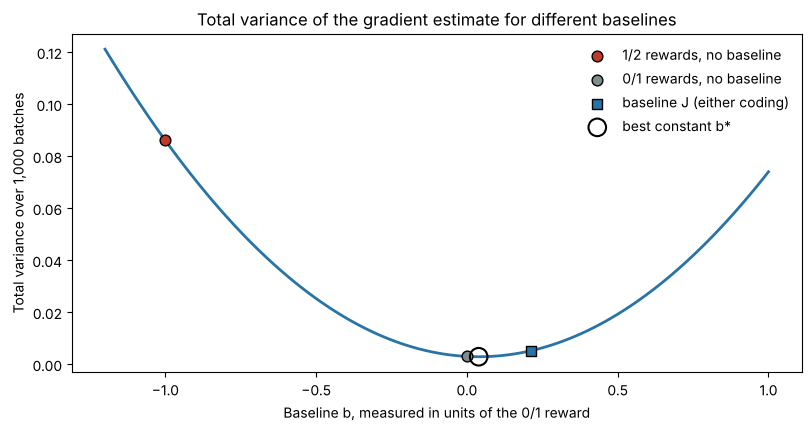

In [5]:
baseline_grid = torch.linspace(-1.2, 1.0, 111)
variance_curve = [total_variance(estimates(0.0, b.item())) for b in baseline_grid]

fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
ax.plot(baseline_grid.tolist(), variance_curve, color="#2874A6", linewidth=2)
markers = [
    (-1.0, "1/2 rewards, no baseline", "#C0392B", "o"),
    (0.0, "0/1 rewards, no baseline", "#7F8C8D", "o"),
    (J, "baseline J (either coding)", "#2874A6", "s"),
]
for b, label, color, shape in markers:
    ax.scatter([b], [total_variance(estimates(0.0, b))], color=color, marker=shape, s=60,
               edgecolor="black", zorder=3, label=label)
ax.scatter([best_baseline], [total_variance(estimates(0.0, best_baseline))], facecolors="none",
           edgecolors="black", s=160, linewidth=1.5, zorder=4, label="best constant b*")
ax.set_title("Total variance of the gradient estimate for different baselines")
ax.set_xlabel("Baseline b, measured in units of the 0/1 reward")
ax.set_ylabel("Total variance over 1,000 batches")
ax.legend(frameon=False)
plt.show()

The curve is a parabola with its minimum near $b^\star$. Moving the baseline away from $b^\star$ in either direction increases the variance, and moving it far away increases the variance a lot: the 1/2 coding without a baseline sits at $b=-1$, high on the left side. A baseline cannot change where the updates go *on average*; it controls how much they scatter around that average.

**Does the answer depend on where the policy is?** The partly trained policy earns reward only about one time in five. Perhaps subtracting the mean helps once correct responses are common. To check, we continue the supervised training from Section 1 and stop at two later checkpoints, after 100 and after 200 supervised updates in total, and repeat the 0/1 comparison at each. Each checkpoint uses the same 1,000-batch procedure as above.

In [6]:
def variance_row(policy):
    J_here, _, g0, mean_grad, batch_means = gradient_study(policy)
    covariance_here = ((g0 - g0.mean(0)) * (mean_grad - mean_grad.mean(0))).sum(1).mean()
    b_star = (covariance_here / total_variance(mean_grad)).item()
    return J_here, b_star, total_variance(g0), total_variance(g0 - J_here * mean_grad), total_variance(g0 - batch_means * mean_grad)


# Continue Section 1's supervised training and save copies after 100 and 200 updates in total.
torch.manual_seed(SEED + 1)
checkpoint_policy = copy.deepcopy(supervised_policy)
checkpoint_optimizer = torch.optim.Adam(checkpoint_policy.parameters(), lr=0.05)
checkpoints = {}
for total_updates in range(31, 201):
    batch = train_numbers[torch.randint(len(train_numbers), (32,))]
    loss = -token_log_probs(checkpoint_policy, batch, correct_rankings(batch)).sum(dim=1).mean()
    checkpoint_optimizer.zero_grad()
    loss.backward()
    checkpoint_optimizer.step()
    if total_updates in (100, 200):
        checkpoints[total_updates] = copy.deepcopy(checkpoint_policy)

# The 30-update row reuses the batches already drawn above.
checkpoint_rows = {30: (J, best_baseline, variance_table[("0/1", "none")],
                        variance_table[("0/1", "J")], variance_table[("0/1", "batch mean")])}
for total_updates, policy in checkpoints.items():
    checkpoint_rows[total_updates] = variance_row(policy)

print("0/1 REWARDS | total variance of the gradient estimate | 1,000 batches of 32")
print("=" * 84)
print(f"{'SFT updates':<13}{'J':>8}{'b*':>8}{'No baseline':>14}{'b = J':>11}{'Batch mean':>13}{'(b = J) / none':>17}")
print("-" * 84)
for updates, (J_here, b_star, none, mean_J, batch_mean) in checkpoint_rows.items():
    print(f"{updates:<13}{J_here:>8.3f}{b_star:>8.3f}{none:>14.4f}{mean_J:>11.4f}{batch_mean:>13.4f}{mean_J / none:>17.2f}")
print("=" * 84)

0/1 REWARDS | total variance of the gradient estimate | 1,000 batches of 32
SFT updates         J      b*   No baseline      b = J   Batch mean   (b = J) / none
------------------------------------------------------------------------------------
30              0.212   0.039        0.0030     0.0052       0.0053             1.73
100             0.545   0.123        0.0043     0.0099       0.0095             2.32
200             0.697   0.140        0.0032     0.0100       0.0096             3.14


**Subtracting the mean does not help at the later checkpoints either.** As the policy improves, $J$ rises from about 0.21 to about 0.70, and the best constant $b^\star$ rises with it, from about 0.04 to about 0.14. But $b^\star$ stays far below $J$. Using $b=J$ or the batch mean gives a larger variance than no baseline at every checkpoint, and the ratio in the last column grows as the policy improves. So $b^\star$ does move with $J$, but at every stage we measured it stays much closer to 0, the value a wrong answer already receives, than to $J$. Whether a constant baseline helps depends on how far the rewards' zero point is from $b^\star$, which is exactly what the 1/2 coding changed.

**Connect to Week 4.** Week 4 asked: if a whole batch receives reward 0, what happens to the gradient? With 0/1 rewards and no baseline, it is zero, so wrong responses never push their own probability down directly. With a positive baseline $b$, each wrong response gets the weight $-b<0$ and becomes less likely. With the batch-mean baseline, an all-zero batch again gives zero, because $\bar r=0$. Section 3 applies the same idea to a group of responses for one prompt.

## 3 · Group-relative advantages

A single baseline for the whole batch ignores the fact that some prompts are harder than others. A ranking of $(4,5,6)$ is easier to get wrong than a ranking of $(1,5,9)$, because the numbers are closer together. **GRPO** therefore samples a **group** of $G$ responses to the same prompt, scores them all, and compares each response only with the others in its group. This gives each prompt its own baseline without any extra model: proximal policy optimization (PPO), the method GRPO modifies, trains a separate value model that predicts the expected reward from each point in a partial response, while GRPO uses the group's average reward instead [(Shao et al., 2024)](https://arxiv.org/abs/2402.03300). For response $i$ in a group with rewards $r_1,\dots,r_G$,

$$
A_i=\frac{r_i-\bar r}{s+\epsilon},
\qquad
\bar r=\frac{1}{G}\sum_{j=1}^{G}r_j,
\qquad
s=\sqrt{\frac{1}{G}\sum_{j=1}^{G}(r_j-\bar r)^2}.
$$

Here $\bar r$ and $s$ are the group's mean and standard deviation, and $\epsilon$ is a small constant (we use $10^{-6}$) that avoids dividing by zero. Each response's log-probability is then weighted by its advantage $A_i$ instead of its reward.

**Two consequences.**

- **Groups with equal rewards give no learning signal.** If all $G$ responses are wrong, or all are correct, every $r_i=\bar r$, so every $A_i=0$. The prompt is either too hard or already solved for the current policy, and it does not change the weights.
- **Shifting or rescaling the rewards does not change the advantages.** Adding a constant to every reward changes $\bar r$ by the same constant. Multiplying every reward by a positive constant multiplies both $r_i-\bar r$ and $s$ by it (apart from the tiny $\epsilon$). The 1/2 coding from Section 2 therefore gives exactly the same advantages as 0/1.

**Dividing by $s$ is a design choice.** Subtracting $\bar r$ is a baseline, so by itself it leaves the expected gradient unchanged (up to a factor $(G-1)/G$, the analogue of Section 2's $(B-1)/B$). Dividing by $s$ gives each group's advantages a standard deviation of about 1, which gives more weight to groups whose rewards are nearly all equal. For example, one correct response out of eight gets a large advantage. This changes how prompts are weighted, so the result is no longer just a rescaled policy gradient. The original GRPO method divides by $s$; some implementations make this optional. Some also divide by $G-1$ inside $s$, which only rescales all advantages by the same factor.

**Work one group by hand.** Take the example prompt (A: 2, B: 7, C: 4) and a group of $G=4$ responses, one of them correct. Then $\bar r=0.25$ and $s=\sqrt{\tfrac14\big(0.75^2+3\times0.25^2\big)}=\sqrt{0.1875}\approx0.4330$:

| Response | Reward $r_i$ | $r_i-\bar r$ | Advantage $A_i$ |
|---|---:|---:|---:|
| `B C A` | 1 | 0.75 | $0.75/0.4330\approx1.732$ |
| `B A C` | 0 | −0.25 | $-0.25/0.4330\approx-0.577$ |
| `C B A` | 0 | −0.25 | $-0.577$ |
| `B B A` | 0 | −0.25 | $-0.577$ |

The advantages add up to zero. The single correct response is pushed up strongly; the three wrong responses are each pushed down a little. Notice that `B A C` and `B B A` begin with the correct first token `B`. The reward judges the whole response, so that correct first token is pushed down along with the rest of the response. Only across many samples does `B` in first place come out ahead, because it appears in rewarded responses more often.

**Compute the advantages.** The code below repeats the hand calculation, then shows the advantages for several reward patterns and for the 1/2 coding. Finally, it samples a real group of $G=8$ responses to the example prompt from the partly trained policy.

In [7]:
EPSILON = 1e-6


def group_advantages(rewards, group_size):
    grouped = rewards.view(-1, group_size)
    mean = grouped.mean(dim=1, keepdim=True)
    std = grouped.std(dim=1, correction=0, keepdim=True)  # divide by G
    return ((grouped - mean) / (std + EPSILON)).view(-1)


hand_responses = torch.tensor([[1, 2, 0], [1, 0, 2], [2, 1, 0], [1, 1, 0]])  # B C A, B A C, C B A, B B A
hand_numbers = demo_numbers.repeat(len(hand_responses), 1)
hand_rewards = ranking_rewards(hand_numbers, hand_responses)
hand_advantages = group_advantages(hand_rewards, len(hand_responses))

print("HAND EXAMPLE | G = 4")
print(f"{'Response':<12}{'Reward':>8}{'r - mean':>12}{'Advantage':>12}")
for response, reward, advantage in zip(hand_responses.tolist(), hand_rewards, hand_advantages):
    print(f"{to_text(response):<12}{reward.item():>8.0f}{(reward - hand_rewards.mean()).item():>12.4f}"
          f"{advantage.item():>12.4f}")
print(f"Group mean = {hand_rewards.mean().item():.4f} | group std = {hand_rewards.std(correction=0).item():.4f}"
      f" | sum of advantages = {hand_advantages.sum().item():.4f}")

print("\n" + "=" * 62)
print(f"{'Rewards in a group of 4':<26}{'Advantages':<36}")
print("-" * 62)
for pattern in [(1, 0, 0, 0), (1, 1, 0, 0), (1, 1, 1, 0), (0, 0, 0, 0), (1, 1, 1, 1), (2, 1, 1, 1)]:
    advantages = group_advantages(torch.tensor(pattern, dtype=torch.float32), 4)
    print(f"{str(pattern):<26}" + "".join(f"{a:>9.3f}" for a in advantages.tolist()))
print("The last row is the first row under the 1/2 coding.")

torch.manual_seed(SEED)
GROUP_SIZE = 8
group_numbers = demo_numbers.repeat(GROUP_SIZE, 1)
group_responses, _ = sample_responses(supervised_policy, group_numbers)
group_rewards = ranking_rewards(group_numbers, group_responses)
sampled_advantages = group_advantages(group_rewards, GROUP_SIZE)

print("\n" + "=" * 62)
print(f"A SAMPLED GROUP | partly trained policy | prompt {EXAMPLE} | G = {GROUP_SIZE}")
print(f"{'Response':<12}{'Reward':>8}{'Advantage':>12}")
for response, reward, advantage in zip(group_responses.tolist(), group_rewards, sampled_advantages):
    print(f"{to_text(response):<12}{reward.item():>8.0f}{advantage.item():>12.4f}")
print(f"Correct responses in the group: {int(group_rewards.sum())} of {GROUP_SIZE}")

HAND EXAMPLE | G = 4
Response      Reward    r - mean   Advantage
B C A              1      0.7500      1.7320
B A C              0     -0.2500     -0.5773
C B A              0     -0.2500     -0.5773
B B A              0     -0.2500     -0.5773
Group mean = 0.2500 | group std = 0.4330 | sum of advantages = 0.0000

Rewards in a group of 4   Advantages                          
--------------------------------------------------------------
(1, 0, 0, 0)                  1.732   -0.577   -0.577   -0.577
(1, 1, 0, 0)                  1.000    1.000   -1.000   -1.000
(1, 1, 1, 0)                  0.577    0.577    0.577   -1.732
(0, 0, 0, 0)                  0.000    0.000    0.000    0.000
(1, 1, 1, 1)                  0.000    0.000    0.000    0.000
(2, 1, 1, 1)                  1.732   -0.577   -0.577   -0.577
The last row is the first row under the 1/2 coding.

A SAMPLED GROUP | partly trained policy | prompt (2, 7, 4) | G = 8
Response      Reward   Advantage
C A B              0     -

The first table reproduces the hand calculation. In the second table, a group with one correct response out of four gives that response a large positive advantage, and a group with three correct responses gives its single wrong response a large negative advantage. Groups in which all rewards are equal get advantages of exactly zero. The last row, which is the first group under the 1/2 coding, has the same advantages as the first row.

In the saved run, three of the eight sampled responses are correct. Each correct response receives the same positive advantage (about 1.29), and each wrong response, including `B C C`, receives the same negative advantage (about −0.77). Change the seed in `torch.manual_seed(SEED)` and rerun the cell to see groups with more or fewer correct responses; if a group has none, all of its advantages are zero.

## 4 · Comparing three training rules

We now train three policies from the uniform start and compare them under identical conditions. Only the advantage that multiplies each log-probability differs:

| Rule | Weight on $\ln\pi_\theta(y_i\mid x_i)$ |
|---|---|
| REINFORCE (Week 4) | $r_i$ |
| Batch-mean baseline | $r_i-\bar r_{\text{batch}}$ |
| Group-relative (GRPO) | $(r_i-\bar r_{\text{group}})/(s_{\text{group}}+\epsilon)$ |

For every rule, the loss for one update is

$$
L(\theta)=-\frac{1}{PG}\sum_{p=1}^{P}\sum_{i=1}^{G}A_{p,i}\,\ln\pi_\theta(y_{p,i}\mid x_p),
$$

where $P$ is the number of prompts per update, $G$ the number of responses per prompt, and $A_{p,i}$ the advantage from the table. All three rules use the same settings: $P=8$ prompts drawn from the training set, $G=8$ sampled responses for each prompt (so $B=64$ responses per update), 300 updates, and Adam with learning rate 0.05, as in Week 4. Each run starts from the same seed. The three rules use their random numbers in the same way, so they see the same prompts in the same order; only the sampled responses differ, because the policies differ. Every 10 updates we record the exact expected reward on the test set. These test-set curves are for display only; nothing (no setting, no stopping point) is chosen using them.

We train each rule twice: once with the 0/1 rewards and once with the 1/2 coding from Section 2 (one extra point for every response). The verifier makes the same decision in both cases; only the numbers attached to "correct" and "wrong" change.

Adam, which we also used in Week 4, rescales each weight's update using running averages of past gradients and of their squares. As a result, multiplying all advantages by a constant has little effect on the updates. The comparison therefore tests the *pattern* of the advantages, not their overall size.

**Predict before running:** with 0/1 rewards, which rule will learn fastest? With the 1/2 coding, which curves will change, and which will stay exactly the same?

In [8]:
NUM_PROMPTS = 8
GROUP_SIZE = 8
NUM_UPDATES = 300
LEARNING_RATE = 0.05
EVAL_EVERY = 10
RULES = ["REINFORCE", "Batch-mean baseline", "GRPO"]


def compute_advantages(rewards, rule, group_size):
    if rule == "REINFORCE":
        return rewards
    if rule == "Batch-mean baseline":
        return rewards - rewards.mean()
    return group_advantages(rewards, group_size)


def train_policy(start_policy, rule, reward_shift=0.0, kl_weight=0.0, reference=None,
                 num_updates=NUM_UPDATES, seed=SEED):
    torch.manual_seed(seed)
    policy = copy.deepcopy(start_policy)
    optimizer = torch.optim.Adam(policy.parameters(), lr=LEARNING_RATE)
    history = []
    for update in range(1, num_updates + 1):
        prompts = train_numbers[torch.randint(len(train_numbers), (NUM_PROMPTS,))]
        batch = prompts.repeat_interleave(GROUP_SIZE, dim=0)  # each prompt G times in a row

        responses, log_probs = sample_responses(policy, batch)
        rewards = ranking_rewards(batch, responses) + reward_shift
        advantages = compute_advantages(rewards, rule, GROUP_SIZE)
        loss = -(advantages * log_probs.sum(dim=1)).mean()
        if kl_weight > 0:  # used in Section 5
            loss = loss + kl_weight * exact_kl(policy, reference, prompts).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if update % EVAL_EVERY == 0:
            record = {"update": update, **measure_performance(policy, test_numbers)}
            if reference is not None:
                with torch.no_grad():
                    record["kl"] = exact_kl(policy, reference, test_numbers).mean().item()
            history.append(record)
    return policy, history


runs = {}
for shift, coding in [(0.0, "0/1"), (1.0, "1/2")]:
    for rule in RULES:
        runs[(coding, rule)] = train_policy(initial_policy, rule, reward_shift=shift)

print(f"TEST SET | {len(test_numbers)} prompts | after {NUM_UPDATES} updates of {NUM_PROMPTS * GROUP_SIZE} responses")
print("=" * 70)
print(f"{'Rewards':<10}{'Rule':<22}{'Expected reward':>17}{'Greedy accuracy':>18}")
print("-" * 70)
start = measure_performance(initial_policy, test_numbers)
print(f"{'-':<10}{'Uniform start':<22}{start['expected_reward']:>17.4f}{start['greedy_accuracy']:>18.1%}")
for (coding, rule), (policy, history) in runs.items():
    final = measure_performance(policy, test_numbers)
    print(f"{coding:<10}{rule:<22}{final['expected_reward']:>17.4f}{final['greedy_accuracy']:>18.1%}")
print("=" * 70)
for rule in RULES[1:]:
    same = all(a["expected_reward"] == b["expected_reward"]
               for a, b in zip(runs[("0/1", rule)][1], runs[("1/2", rule)][1]))
    print(f"{rule}: identical curves under the two codings? {same}")

TEST SET | 120 prompts | after 300 updates of 64 responses
Rewards   Rule                    Expected reward   Greedy accuracy
----------------------------------------------------------------------
-         Uniform start                    0.0370              0.0%
0/1       REINFORCE                        0.7533            100.0%
0/1       Batch-mean baseline              0.7366            100.0%
0/1       GRPO                             0.7246            100.0%
1/2       REINFORCE                        0.3526             60.8%
1/2       Batch-mean baseline              0.7366            100.0%
1/2       GRPO                             0.7246            100.0%
Batch-mean baseline: identical curves under the two codings? True
GRPO: identical curves under the two codings? True


**Plot the learning curves.** Each panel shows the exact expected reward on the test set during training. The left panel uses the 0/1 rewards; the right panel uses the 1/2 coding. In the right panel, the batch-mean and GRPO curves are drawn dashed and dotted so that you can see they lie exactly on top of their 0/1 versions.

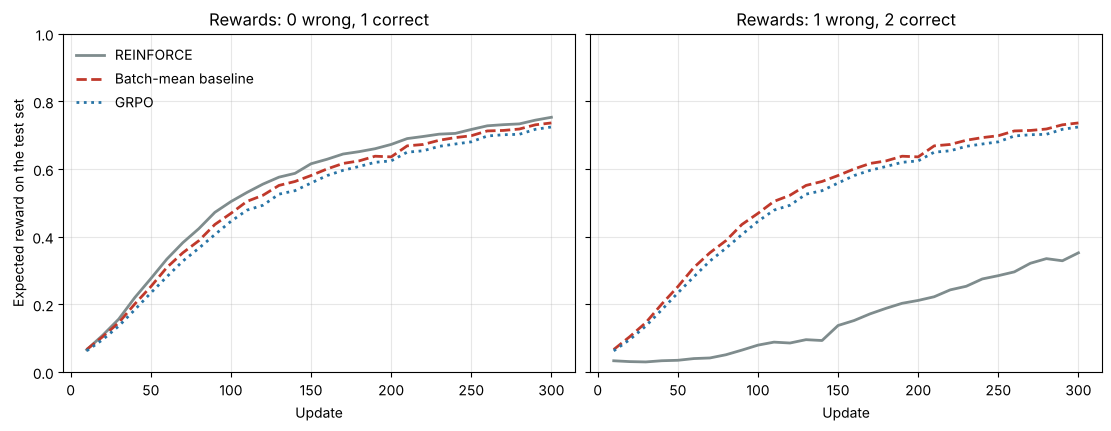

In [9]:
colors = {"REINFORCE": "#7F8C8D", "Batch-mean baseline": "#C0392B", "GRPO": "#2874A6"}
styles = {"REINFORCE": "-", "Batch-mean baseline": "--", "GRPO": ":"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, constrained_layout=True)
for ax, coding, title in [(axes[0], "0/1", "Rewards: 0 wrong, 1 correct"),
                          (axes[1], "1/2", "Rewards: 1 wrong, 2 correct")]:
    for rule in RULES:
        history = runs[(coding, rule)][1]
        ax.plot([h["update"] for h in history], [h["expected_reward"] for h in history],
                color=colors[rule], linestyle=styles[rule], linewidth=2, label=rule)
    ax.set_title(title)
    ax.set_xlabel("Update")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Expected reward on the test set")
axes[0].legend(frameon=False, loc="upper left")
plt.show()

**With 0/1 rewards (left), the three rules learn at a similar pace.** All three reach 100% greedy accuracy on the test set, and their expected rewards end close together: plain REINFORCE slightly ahead, GRPO slightly behind. This is consistent with Section 2: with 0/1 rewards, 0 is already a good reference point, and subtracting the mean did not reduce the variance at any of the checkpoints we measured. GRPO's division by the group standard deviation changes how prompts are weighted; on this task, that does not speed up learning.

**With the 1/2 coding (right), REINFORCE learns much more slowly.** Its greedy accuracy after 300 updates is far below 100%. Every sampled response now receives a positive weight, so its updates are much noisier, as the variance study predicted. The batch-mean and GRPO curves are *exactly* the same as in the left panel: both rules subtract a mean, so the extra point cancels before it can affect any update.

The benefit of a baseline is therefore not that it always speeds up learning. With a baseline that tracks the average reward ($J$, the batch mean, or the group mean), the update depends only on how each reward compares with that average, so the reward function's arbitrary zero point no longer matters. GRPO's group mean also adapts that average to each prompt.

**Check that the comparison is not a fluke of one seed.** One run per rule can mislead. The next cell repeats the 300-update runs with five seeds and reports the mean, smallest, and largest final test expected reward. To save time, we do not rerun the batch-mean and GRPO rules under the 1/2 coding, because their results are identical to the 0/1 runs.

In [10]:
SEEDS = [SEED + k for k in range(5)]
seed_results = {}
for coding, shift, rule in [("0/1", 0.0, "REINFORCE"), ("0/1", 0.0, "Batch-mean baseline"),
                            ("0/1", 0.0, "GRPO"), ("1/2", 1.0, "REINFORCE")]:
    finals = [measure_performance(runs[(coding, rule)][0], test_numbers)["expected_reward"]]  # seed 425: run above
    for seed in SEEDS[1:]:
        policy, _ = train_policy(initial_policy, rule, reward_shift=shift, seed=seed)
        finals.append(measure_performance(policy, test_numbers)["expected_reward"])
    seed_results[(coding, rule)] = finals

print(f"FINAL TEST EXPECTED REWARD | {len(SEEDS)} seeds | {NUM_UPDATES} updates each")
print("=" * 64)
print(f"{'Rewards':<10}{'Rule':<22}{'Mean':>10}{'Smallest':>11}{'Largest':>11}")
print("-" * 64)
for (coding, rule), finals in seed_results.items():
    print(f"{coding:<10}{rule:<22}{sum(finals) / len(finals):>10.4f}{min(finals):>11.4f}{max(finals):>11.4f}")
print("=" * 64)

FINAL TEST EXPECTED REWARD | 5 seeds | 300 updates each
Rewards   Rule                        Mean   Smallest    Largest
----------------------------------------------------------------
0/1       REINFORCE                 0.7508     0.7422     0.7541
0/1       Batch-mean baseline       0.7355     0.7259     0.7434
0/1       GRPO                      0.7235     0.7073     0.7333
1/2       REINFORCE                 0.3586     0.2224     0.4398


Across seeds, the three rules with 0/1 rewards end within a few hundredths of each other, in the same order on average as the single run above: REINFORCE, then the batch-mean baseline, then GRPO (the batch-mean rule's range overlaps both others). Every seed of REINFORCE with 1/2 rewards ends far below every seed of the other three rows. **Discuss:** in a language-model task, rewards often combine several parts (correctness, format, length). Why would a method whose updates ignore a constant added to every reward be convenient there?

**Try it:** inspect the GRPO policy trained with 0/1 rewards on a prompt of your choice. Set `YOUR_NUMBERS` to three different integers from 1 through 9. The cell prints the greedy response one token at a time and the probability of the correct ranking under the uniform start, the partly trained policy, and the GRPO policy. Predict the greedy response before running it. Try numbers that are close together, such as `(4, 5, 6)`.

In [11]:
YOUR_NUMBERS = (3, 8, 6)

if (len(YOUR_NUMBERS) != 3 or len(set(YOUR_NUMBERS)) != 3
        or any(type(value) is not int or not 1 <= value <= 9 for value in YOUR_NUMBERS)):
    raise ValueError("Choose three different integers from 1 through 9.")

grpo_policy = runs[("0/1", "GRPO")][0]
numbers = torch.tensor([YOUR_NUMBERS], dtype=torch.float32)
greedy = greedy_responses(grpo_policy, numbers)[0].tolist()
correct = correct_rankings(numbers)

print(format_prompt(YOUR_NUMBERS))
print("-" * 71)
print(f"GREEDY RESPONSE OF THE GRPO POLICY: {to_text(greedy)}")
show_response(grpo_policy, YOUR_NUMBERS, greedy)
print("-" * 71)
print(f"Correct ranking: {to_text(correct[0].tolist())}")
for name, policy in [("Uniform start", initial_policy), ("Partly trained (SFT)", supervised_policy),
                     ("GRPO, 0/1 rewards", grpo_policy)]:
    with torch.no_grad():
        p_correct = token_log_probs(policy, numbers, correct).sum().exp().item()
    print(f"{name:<24}P(correct ranking) = {p_correct:.4f}")

Rank the letters from largest to smallest number.
A: 3    B: 8    C: 6
Respond with three letters.
-----------------------------------------------------------------------
GREEDY RESPONSE OF THE GRPO POLICY: B C A
Position  Chosen before      P(A)    P(B)    P(C)   Token   ln p(token)
1         (none)           0.0054  0.8816  0.1130       B       -0.1260
2         B                0.0430  0.0002  0.9568       C       -0.0442
3         B C              0.9958  0.0039  0.0003       A       -0.0042
Sum of token log-probabilities = -0.1744
Probability of the whole response = exp(-0.1744) = 0.8400
-----------------------------------------------------------------------
Correct ranking: B C A
Uniform start           P(correct ranking) = 0.0370
Partly trained (SFT)    P(correct ranking) = 0.2332
GRPO, 0/1 rewards       P(correct ranking) = 0.8400


## 5 · Staying close to a reference policy

When a language model is trained with rewards, the starting model already writes fluent text. We usually do not want reinforcement learning to change its behavior more than needed to earn reward. A common safeguard is a penalty for moving away from a fixed copy of the starting model, the **reference policy** $\pi_{\text{ref}}$.

**The KL divergence.** For one prompt, the Kullback–Leibler (KL) divergence from the reference to the current policy is

$$
\mathrm{KL}\big(\pi_\theta(\cdot\mid x)\,\big\|\,\pi_{\text{ref}}(\cdot\mid x)\big)
=\sum_{y}\pi_\theta(y\mid x)\,\ln\frac{\pi_\theta(y\mid x)}{\pi_{\text{ref}}(y\mid x)}
=\mathbb{E}_{y\sim\pi_\theta(\cdot\mid x)}\big[\ln\pi_\theta(y\mid x)-\ln\pi_{\text{ref}}(y\mid x)\big].
$$

It is never negative, and it equals zero only when the two policies give every response the same probability. It is measured in nats, like Week 1's loss. We add it to the GRPO loss with a weight $\beta\ge0$:

$$
L(\theta)=-\frac{1}{PG}\sum_{p,i}A_{p,i}\ln\pi_\theta(y_{p,i}\mid x_p)
\;+\;\beta\,\frac{1}{P}\sum_{p=1}^{P}\mathrm{KL}\big(\pi_\theta(\cdot\mid x_p)\,\big\|\,\pi_{\text{ref}}(\cdot\mid x_p)\big).
$$

The first term rewards responses that beat their group; the second pulls the policy back toward the reference. A larger $\beta$ gives the penalty more weight. Because GRPO's advantages are standardized, $\beta$ is measured relative to advantages of size about 1, not relative to the raw reward.

**Computing the KL.** With only 27 possible responses, we compute the KL exactly by summing over all of them, and autograd differentiates it. A language model has far too many possible responses for that, so GRPO estimates the KL from the sampled tokens instead (see the language-model connection below).

**The experiment.** The reference is the partly trained policy from Section 1. Each run starts *at* the reference, so the KL starts at 0, and trains with GRPO and 0/1 rewards for 300 updates with $\beta\in\{0,0.5,2\}$. We report the test-set expected reward, greedy accuracy, and the average KL over test prompts.

**Predict before running:** which value of $\beta$ will end with the highest expected reward? Which will end closest to the reference?

GRPO FROM THE REFERENCE POLICY | 300 updates | test set
Policy                  Expected reward  Greedy accuracy   KL to reference
--------------------------------------------------------------------------
Reference                        0.2119           100.0%            0.0000
GRPO, beta = 0.0                 0.7410           100.0%            0.8717
GRPO, beta = 0.5                 0.6559           100.0%            0.6898
GRPO, beta = 2.0                 0.2857           100.0%            0.0477


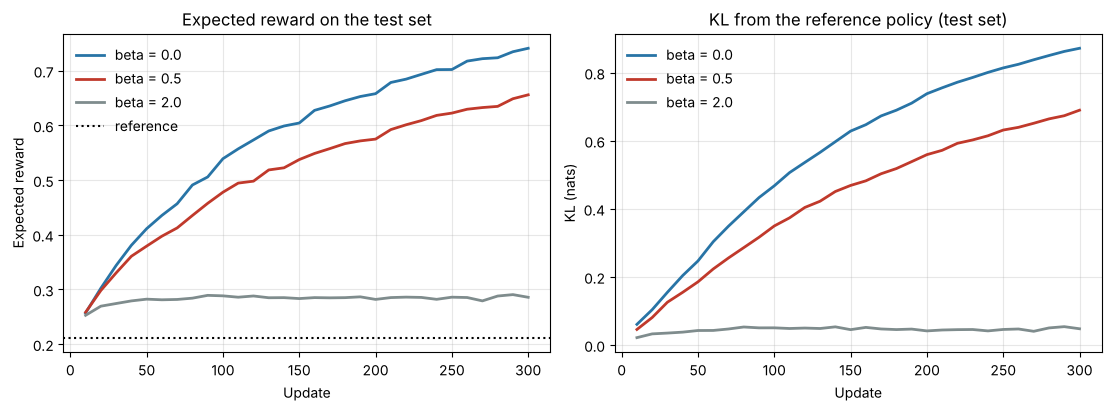

In [12]:
ALL_RESPONSES = torch.tensor(list(itertools.product(range(3), repeat=RESPONSE_LENGTH)))  # all 27


def all_response_log_probs(policy, numbers):
    # Log-probability of each of the 27 responses for each prompt: shape (prompts, 27).
    repeated_numbers = numbers.repeat_interleave(len(ALL_RESPONSES), dim=0)
    repeated_responses = ALL_RESPONSES.repeat(len(numbers), 1)
    return token_log_probs(policy, repeated_numbers, repeated_responses).sum(dim=1).view(len(numbers), -1)


def exact_kl(policy, reference, numbers):
    log_p = all_response_log_probs(policy, numbers)
    with torch.no_grad():
        log_p_ref = all_response_log_probs(reference, numbers)
    return (log_p.exp() * (log_p - log_p_ref)).sum(dim=1)


BETAS = [0.0, 0.5, 2.0]
reference_policy = copy.deepcopy(supervised_policy)  # a fixed copy; it is never updated

kl_runs = {beta: train_policy(reference_policy, "GRPO", kl_weight=beta, reference=reference_policy)
           for beta in BETAS}

print(f"GRPO FROM THE REFERENCE POLICY | {NUM_UPDATES} updates | test set")
print("=" * 74)
print(f"{'Policy':<22}{'Expected reward':>17}{'Greedy accuracy':>17}{'KL to reference':>18}")
print("-" * 74)
reference_metrics = measure_performance(reference_policy, test_numbers)
print(f"{'Reference':<22}{reference_metrics['expected_reward']:>17.4f}"
      f"{reference_metrics['greedy_accuracy']:>17.1%}{0.0:>18.4f}")
for beta, (policy, history) in kl_runs.items():
    final = history[-1]
    print(f"{f'GRPO, beta = {beta}':<22}{final['expected_reward']:>17.4f}"
          f"{final['greedy_accuracy']:>17.1%}{final['kl']:>18.4f}")
print("=" * 74)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for beta, color in zip(BETAS, ["#2874A6", "#C0392B", "#7F8C8D"]):
    history = kl_runs[beta][1]
    updates = [h["update"] for h in history]
    axes[0].plot(updates, [h["expected_reward"] for h in history], color=color, linewidth=2, label=f"beta = {beta}")
    axes[1].plot(updates, [h["kl"] for h in history], color=color, linewidth=2, label=f"beta = {beta}")
axes[0].axhline(reference_metrics["expected_reward"], color="black", linestyle=":", label="reference")
axes[0].set_title("Expected reward on the test set")
axes[1].set_title("KL from the reference policy (test set)")
axes[0].set_ylabel("Expected reward")
axes[1].set_ylabel("KL (nats)")
for ax in axes:
    ax.set_xlabel("Update")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)
plt.show()

Without a penalty ($\beta=0$), the policy earns the highest expected reward and moves furthest from the reference. As $\beta$ grows, the KL stays smaller and the expected reward rises less above the reference's value. **$\beta$ trades reward against closeness to the reference.** With $\beta=2$, the KL levels off early and the expected reward stays only a little above the reference's value: the pull toward the reference balances the push from the advantages.

Here the reference is simply a less-trained version of the same rule, so staying close to it only costs reward. For a language model, the reference also carries everything the pretrained model knows about writing fluent text. The penalty limits how far a narrow reward can pull the model away from that behavior, for example toward odd text that happens to satisfy a flawed verifier.

**Try it:** change `BETAS` (for example, to `[0.0, 0.1, 5.0]`) and rerun the cell. Predict where each curve will end before running.

### How this maps to a language model

GRPO for a language model follows the same steps as our training loop [(Shao et al., 2024)](https://arxiv.org/abs/2402.03300):

1. **Sample a group.** For each prompt (for example, a math problem), sample $G$ complete responses from the current model, token by token, as in Week 3.
2. **Verify.** A verifier scores each response, for example by checking its final answer. Several reward functions can be added together.
3. **Compute group-relative advantages.** Standardize the rewards within each group: $A_i=(r_i-\bar r)/(s+\epsilon)$. Every token of response $i$ receives the same advantage $A_i$.
4. **Update with a KL penalty.** Increase the log-probability of tokens in responses with positive advantages and decrease it for negative ones. The response log-probability is the sum of its token log-probabilities, as in Section 1. A penalty keeps the model close to the reference model, usually the model at the start of reinforcement learning. Because the model cannot sum over all possible responses, GRPO estimates the KL at each sampled token from $\pi_{\text{ref}}/\pi_\theta$ for that token, using an estimate that is never negative.

Real implementations also use a clipped **importance-ratio** objective with the ratio $\pi_\theta/\pi_{\theta_{\text{old}}}$, as in PPO, which matters when one batch of samples is reused for several updates. We do not cover it here. They also average the loss over tokens, because responses have different lengths; ours all have three tokens.

**In practice.** Hugging Face's TRL library implements GRPO. A reward function receives the generated completions (plus any extra dataset columns, such as the correct answer) and returns one number per completion. The sketch below is not run in this notebook; the model name and the dataset are placeholders.

```python
from datasets import Dataset
from trl import GRPOConfig, GRPOTrainer

train_dataset = Dataset.from_list([
    {"prompt": "Rank the letters from largest to smallest number.\nA: 2    B: 7    C: 4\nAnswer:",
     "answer": "B C A"},
    # ... many more prompts
])


def ranking_reward(completions, answer, **kwargs):
    # The verifier: 1.0 for an exactly correct ranking, 0.0 otherwise.
    return [1.0 if completion.strip() == target else 0.0
            for completion, target in zip(completions, answer)]


args = GRPOConfig(
    output_dir="grpo-ranking",
    num_generations=8,        # group size G
    beta=0.04,                # KL weight; recent TRL versions default to 0.0 (no KL penalty)
    learning_rate=1e-6,
    max_completion_length=16,
)
trainer = GRPOTrainer(
    model="your-model-name",  # a pretrained or fine-tuned causal language model
    reward_funcs=ranking_reward,
    args=args,
    train_dataset=train_dataset,
)
trainer.train()
```

The library samples the groups, calls the reward function, computes the advantages, and applies the update; options such as whether to divide by the group standard deviation are set in `GRPOConfig`.

## Recap

We extended Week 4's update to multi-token responses and replaced raw rewards with advantages:

**Prompt → group of sampled responses → verifier rewards → group-relative advantages → KL-penalized loss → weight update**

A response's log-probability is the sum of its token log-probabilities. Subtracting a baseline from the rewards leaves the expected gradient unchanged because $\mathbb{E}[\nabla_\theta\ln\pi_\theta]=0$; it changes only the variance. Subtracting a mean-based baseline ($J$, the batch mean, or the group mean) makes the update independent of the reward's arbitrary zero point, but subtracting the mean is not automatically the variance-minimizing choice. GRPO uses each prompt's group of responses as its baseline and standardizes the result, so groups with equal rewards contribute nothing. A KL penalty keeps the trained policy near a reference policy, at some cost in reward.

### Check your understanding

1. Why does subtracting a constant baseline $b$ leave the expected policy gradient unchanged?
2. In GRPO, what happens to a group in which all $G$ responses are correct? Is that a problem?
3. A response `B A C` to the prompt (A: 2, B: 7, C: 4) earns reward 0 even though its first token is correct. What does the update do to that first token, and why does training still learn to put `B` first?
4. In Section 4, why did adding 1 to every reward slow down REINFORCE but leave GRPO's curve exactly unchanged?
5. What does a larger $\beta$ trade off?

<details><summary>Answers · open after discussing</summary>

1. The expected value of $\nabla_\theta\ln\pi_\theta(y\mid x)$ under the policy is $\nabla_\theta\sum_y\pi_\theta(y\mid x)=\nabla_\theta1=0$. The baseline term $b\,\nabla_\theta\ln\pi_\theta$ therefore has expected value zero, so only the variance can change.
2. Every advantage is zero, so the group does not change the weights. The policy already solves that prompt; the group's sampled responses are spent without a learning signal. If most groups are all correct or all wrong, training slows down, which is one reason prompts of suitable difficulty matter.
3. The whole response gets one advantage, so with a baseline every token in `B A C`, including the correct `B`, becomes less likely. Across many samples, responses that start with `B` are correct more often than those that do not, so on average the updates still favor `B` in first place. This is the **credit assignment** problem: a reward for a whole response does not say which tokens deserved it, and longer responses make the problem harder.
4. With the 1/2 coding, every REINFORCE weight is positive, so each update pushes up all sampled responses and its noise grows (Section 2). GRPO subtracts the group mean, which removes the extra point exactly, so its advantages and updates are identical.
5. Reward against closeness to the reference policy. A larger $\beta$ keeps the policy nearer to the reference (smaller KL) but typically earns less reward; $\beta=0$ lets the policy move as far as the reward pushes it.

</details>

### Next week: learning to report uncertainty

A correct answer and a well-calibrated statement of confidence are different goals. Next week, the model gives an answer and a reported probability $q$ that the answer is correct, and the reward $R=c-(q-c)^2$ scores both, where $c$ is 1 for a correct answer and 0 otherwise. This is reinforcement learning with calibration rewards (RLCR). We will see why the squared (Brier) penalty is a **proper scoring rule**, which makes reporting your true probability the best strategy, and how to check calibration across many answers. We will reuse today's group-mean baseline.

## References and further reading

- [Williams (1992): REINFORCE](https://gwern.net/doc/reinforcement-learning/model-free/1992-williams.pdf): policy gradients and reward baselines.
- [Shao et al. (2024): DeepSeekMath](https://arxiv.org/abs/2402.03300): introduces group relative policy optimization (GRPO).
- [OpenAI Spinning Up: Introduction to policy optimization](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html): baselines and advantage functions.
- [Hugging Face TRL: GRPO Trainer](https://huggingface.co/docs/trl/grpo_trainer): GRPO for language models in practice.